# Introducción práctica al Procesamiento de Lenguaje Natural
## De texto sin estructura a un pipeline evaluable


### Objetivos
Al terminar este notebook podrá:

- explicar las tareas y dificultades básicas del PLN;
- construir un pipeline de preprocesamiento;
- usar tokenización, stemming, lematización, POS, dependencias y entidades;
- representar documentos con conteos y TF-IDF;
- medir similitud entre textos;
- entrenar y evaluar un clasificador clásico;
- analizar errores, sesgo y límites del sistema.

## Mapa del notebook

| Sección | Tiempo |
|---|---:|
| 1. ¿Qué es PLN? y ambigüedad | 7 min |
| 2. Unidades: corpus, documento, oración, token y tipo | 6 min |
| 3. Normalización y tokenización | 10 min |
| 4. Stopwords, stemming y lematización | 8 min |
| 5. POS, dependencias y entidades | 10 min |
| 6. Bolsa de palabras, TF-IDF y similitud | 12 min |
| 7. Clasificación de texto de extremo a extremo | 20 min |
| 8. Evaluación, errores y sesgo | 5 min |
| 9. Cierre | 2 min |

## 0. Verificación del entorno

El núcleo usa `re`, `collections`, `pandas`, `scikit-learn`, `nltk` y `spaCy`. El modelo lingüístico completo de spaCy es opcional; si no está instalado, el notebook usa un pipeline básico de español y explica cómo habilitar POS, dependencias, lematización y entidades.

In [ ]:
import re
import sys
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from nltk.stem.snowball import SnowballStemmer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
)

print("Python:", sys.version.split()[0])
print("Entorno base cargado correctamente")

Python: 3.13.18
Entorno base cargado correctamente


### spaCy en español

Para habilitar el análisis lingüístico completo, ejecute una vez en una terminal (este entorno es de `uv` y no tiene `pip`, por eso `%pip install` y `python -m spacy download` fallan):

```bash
uv pip install https://github.com/explosion/spacy-models/releases/download/es_core_news_sm-3.8.0/es_core_news_sm-3.8.0-py3-none-any.whl
```

In [ ]:
import spacy

try:
    nlp = spacy.load("es_core_news_sm")
    MODELO_SPACY_COMPLETO = True
    print("✅ Modelo es_core_news_sm cargado")
except OSError:
    nlp = spacy.blank("es")
    nlp.add_pipe("sentencizer")
    MODELO_SPACY_COMPLETO = False
    print("⚠️ Se usa spacy.blank('es'). Tokenización disponible; POS, dependencias, lemas y NER requieren es_core_news_sm.")

⚠️ Se usa spacy.blank('es'). Tokenización disponible; POS, dependencias, lemas y NER requieren es_core_news_sm.


# 1. ¿Qué es Procesamiento de Lenguaje Natural? — 7 minutos

El **Procesamiento de Lenguaje Natural (PLN)** estudia métodos computacionales para analizar, representar, comprender o generar lenguaje humano.

### Ejemplos de tareas

- clasificación de documentos;
- análisis de sentimientos;
- extracción de entidades y relaciones;
- búsqueda y recuperación de información;
- traducción automática;
- resumen;
- respuesta a preguntas;
- sistemas conversacionales;
- generación de texto.

### Un pipeline clásico

```text
Texto bruto
   ↓
Limpieza y segmentación
   ↓
Características lingüísticas o estadísticas
   ↓
Representación numérica
   ↓
Modelo o reglas
   ↓
Predicción
   ↓
Evaluación y análisis de errores
```

## El reto central: la ambigüedad

El lenguaje no es una tabla perfectamente estructurada.

- **Léxica:** “banco” puede ser una entidad financiera o un asiento.
- **Sintáctica:** “Vi al estudiante con el telescopio”. ¿Quién tenía el telescopio?
- **Semántica:** “La película estuvo pesada” puede referirse al peso o a una experiencia difícil.
- **Pragmática:** “¿Puedes abrir la ventana?” formalmente es una pregunta de capacidad, pero normalmente es una petición.
- **Referencial:** “María habló con Ana y ella presentó el informe”. ¿Quién presentó?

In [ ]:
frases_ambiguas = [
    "Fui al banco a retirar dinero.",
    "Me senté en el banco del parque.",
    "Vi al estudiante con el telescopio.",
    "¿Puedes abrir la ventana?",
]

for i, frase in enumerate(frases_ambiguas, start=1):
    print(i, frase)

1 Fui al banco a retirar dinero.
2 Me senté en el banco del parque.
3 Vi al estudiante con el telescopio.
4 ¿Puedes abrir la ventana?


### Pregunta al grupo

¿Qué información adicional necesitaría un sistema para interpretar correctamente cada frase: palabras cercanas, estructura sintáctica, conocimiento del mundo, intención del hablante o contexto conversacional?

### Respuesta

| Frase | Tipo de ambigüedad | Qué necesita el sistema |
|---|---|---|
| "Fui al banco a retirar dinero." | Léxica | **Palabras cercanas.** "retirar dinero" basta para elegir el sentido de entidad financiera. |
| "Me senté en el banco del parque." | Léxica | **Palabras cercanas.** "me senté" y "parque" apuntan al asiento. |
| "Vi al estudiante con el telescopio." | Sintáctica | **Estructura sintáctica y contexto conversacional.** |
| "¿Puedes abrir la ventana?" | Pragmática | **Intención del hablante y conocimiento del mundo.** |

- **Las dos frases de "banco"** se resuelven con el contexto local: las palabras vecinas son suficientes, y por eso incluso modelos sencillos basados en coocurrencias suelen acertar.
- **La del telescopio** no se resuelve con las palabras vecinas. Hay dos análisis sintácticos válidos: "con el telescopio" modifica a "vi" (yo usé el telescopio) o a "estudiante" (el estudiante lo tenía). La sintaxis muestra las dos opciones, pero para elegir hace falta el contexto previo, por ejemplo si antes se dijo quién tenía un telescopio.
- **La de la ventana** se entiende sin problema en lo literal, pero el significado literal no es el que importa. Formalmente pregunta por una capacidad; para interpretarla como petición el sistema debe reconocer la intención del hablante y saber que, por convención social, esa forma se usa para pedir algo cortésmente.

**Conclusión:** la información necesaria crece de lo local a lo global: palabras vecinas → estructura de la oración → conversación previa → conocimiento del mundo e intención. Las técnicas clásicas de este notebook (BoW, TF-IDF) solo capturan el primer nivel, y por eso los modelos contextuales manejan mejor los demás.

# 2. Unidades fundamentales — 6 minutos

- **Corpus:** colección de documentos.
- **Documento:** unidad textual procesada como un elemento.
- **Oración:** segmento que expresa una unidad gramatical.
- **Token:** ocurrencia concreta de una unidad textual.
- **Tipo:** forma única dentro del vocabulario.
- **Vocabulario:** conjunto de tipos considerados por el sistema.

Ejemplo: en “PLN aprende y PLN transforma”, hay 5 tokens si se separa por espacios, pero 4 tipos después de normalizar.

In [ ]:
texto = "PLN aprende y PLN transforma"
tokens = texto.lower().split()
tipos = sorted(set(tokens))

print("Tokens:", tokens)
print("Número de tokens:", len(tokens))
print("Tipos:", tipos)
print("Tamaño del vocabulario:", len(tipos))

Tokens: ['pln', 'aprende', 'y', 'pln', 'transforma']
Número de tokens: 5
Tipos: ['aprende', 'pln', 'transforma', 'y']
Tamaño del vocabulario: 4


## Frecuencia y distribución

Contar tokens es una operación simple, pero útil para explorar un corpus, detectar términos dominantes y verificar calidad.

In [ ]:
corpus_pequeno = [
    "La inteligencia artificial procesa lenguaje",
    "El lenguaje expresa conocimiento",
    "La inteligencia artificial aprende de datos",
]

todos_los_tokens = " ".join(corpus_pequeno).lower().split()
frecuencias = Counter(todos_los_tokens)
frecuencias.most_common()

[('la', 2),
 ('inteligencia', 2),
 ('artificial', 2),
 ('lenguaje', 2),
 ('procesa', 1),
 ('el', 1),
 ('expresa', 1),
 ('conocimiento', 1),
 ('aprende', 1),
 ('de', 1),
 ('datos', 1)]

# 3. Normalización y tokenización — 10 minutos

## 3.1 Normalización

Normalizar significa reducir variaciones que no son relevantes para la tarea. No existe una receta universal.

Operaciones comunes:

- convertir a minúsculas;
- normalizar espacios;
- tratar URLs, correos, números o menciones;
- decidir qué hacer con tildes y signos;
- corregir o conservar errores ortográficos;
- preservar información de dominio.

> Una transformación útil para clasificación temática puede destruir información necesaria para reconocimiento de nombres propios o análisis jurídico.

In [ ]:
texto_ruidoso = "  Contáctame en Ana.Perez@Ejemplo.com!!! El precio fue $1,250.00.  "

normalizado = texto_ruidoso.strip().lower()
normalizado = re.sub(r"\s+", " ", normalizado)
normalizado_con_marcas = re.sub(r"[\w.+-]+@[\w.-]+\.[a-zA-Z]{2,}", "<EMAIL>", normalizado)
normalizado_con_marcas = re.sub(r"\$?[\d,.]+", "<NUM>", normalizado_con_marcas)

print("Original:   ", repr(texto_ruidoso))
print("Normalizado:", normalizado)
print("Con marcas: ", normalizado_con_marcas)

Original:    '  Contáctame en Ana.Perez@Ejemplo.com!!! El precio fue $1,250.00.  '
Normalizado: contáctame en ana.perez@ejemplo.com!!! el precio fue $1,250.00.
Con marcas:  contáctame en <EMAIL>!!! el precio fue <NUM>


## 3.2 Tokenización

Tokenizar es segmentar una cadena en unidades. `split()` es útil para aprender Python, pero no maneja bien puntuación, contracciones, URLs o reglas específicas del idioma.

In [ ]:
frase = "¡Hola, Andrés! ¿El curso de PLN empieza a las 6:30 p. m.?"

print("split():")
print(frase.split())

print("\nRegex simple:")
print(re.findall(r"\b\w+(?:[-']\w+)*\b", frase.lower(), flags=re.UNICODE))

print("\nspaCy:")
doc = nlp(frase)
print([token.text for token in doc])

split():
['¡Hola,', 'Andrés!', '¿El', 'curso', 'de', 'PLN', 'empieza', 'a', 'las', '6:30', 'p.', 'm.?']

Regex simple:
['hola', 'andrés', 'el', 'curso', 'de', 'pln', 'empieza', 'a', 'las', '6', '30', 'p', 'm']

spaCy:
['¡', 'Hola', ',', 'Andrés', '!', '¿', 'El', 'curso', 'de', 'PLN', 'empieza', 'a', 'las', '6:30', 'p.', 'm.', '?']


## 3.3 Una función reproducible de preprocesamiento

La función debe hacer explícitas las decisiones. Aquí conservamos letras, números y tildes; convertimos a minúsculas y eliminamos puntuación.

In [ ]:
def tokenizar_basico(texto: str) -> list[str]:
    texto = texto.lower().strip()
    return re.findall(r"\b\w+\b", texto, flags=re.UNICODE)

for ejemplo in [
    "¡Excelente curso!",
    "PLN-2026: sesión 1.",
    "Correo: estudiante@universidad.edu",
]:
    print(ejemplo, "->", tokenizar_basico(ejemplo))

¡Excelente curso! -> ['excelente', 'curso']
PLN-2026: sesión 1. -> ['pln', '2026', 'sesión', '1']
Correo: estudiante@universidad.edu -> ['correo', 'estudiante', 'universidad', 'edu']


### Microejercicio

¿Qué cambiaría si la tarea fuera detectar correos electrónicos? ¿Conviene partir `estudiante@universidad.edu` en varias piezas o conservarlo como una unidad?

### Solución

**Conviene conservarlo como una unidad.** Si la tarea es detectar correos, el correo completo *es* la entidad que se busca. `tokenizar_basico` lo parte en `['estudiante', 'universidad', 'edu']` y elimina la `@` y el punto, que son precisamente las señales que lo identifican; después de eso ya no se puede saber que esas tres palabras formaban un correo.

**Qué cambiaría en el pipeline:**

- **Orden de las reglas:** el patrón de correo debe probarse *antes* que el patrón general de palabras, para que tenga prioridad.
- **Puntuación:** ya no se puede eliminar toda; `@`, `.`, `-`, `_` y `+` son parte del token cuando están dentro de un correo.
- **Minúsculas:** siguen siendo aceptables, porque en la práctica los correos no distinguen mayúsculas.
- **Normalización:** depende del objetivo. Para *extraer* correos se conserva el valor; para *clasificar* textos suele bastar con reemplazarlo por una marca como `<EMAIL>` (sección 3.1), que reduce vocabulario y protege datos personales.

La misma idea aplica a URLs, fechas, montos o números de contrato: la tokenización se decide según la tarea.

In [ ]:
PATRON_EMAIL = r"[\w.+-]+@[\w.-]+\.\w{2,}"

def tokenizar_con_correos(texto: str) -> list[str]:
    # El patrón de correo va primero: en una alternancia gana la primera opción que coincide.
    return re.findall(rf"{PATRON_EMAIL}|\w+", texto.lower().strip())

for ejemplo in [
    "Correo: estudiante@universidad.edu",
    "Escriba a Ana.Perez@Ejemplo.com.",
    "PLN-2026: sesión 1.",
]:
    print(ejemplo)
    print("  básico:     ", tokenizar_basico(ejemplo))
    print("  con correos:", tokenizar_con_correos(ejemplo))

# 4. Palabras vacías, stemming y lematización — 8 minutos

## 4.1 Palabras vacías (*stopwords*)

Son palabras muy frecuentes que a veces aportan poca discriminación para una tarea concreta. Sin embargo, eliminarlas indiscriminadamente puede borrar negación o estructura.

Ejemplo crítico: “**no** recomiendo este producto”. Si se elimina “no”, cambia el significado.

In [ ]:
stopwords_demo = {
    "el", "la", "los", "las", "un", "una", "de", "del", "y", "o", "que", "en", "a", "por", "para"
}

frase = "No recomiendo el servicio porque la respuesta fue lenta"
tokens = tokenizar_basico(frase)
filtrados = [t for t in tokens if t not in stopwords_demo]

print("Tokens:    ", tokens)
print("Filtrados: ", filtrados)

Tokens:     ['no', 'recomiendo', 'el', 'servicio', 'porque', 'la', 'respuesta', 'fue', 'lenta']
Filtrados:  ['no', 'recomiendo', 'servicio', 'porque', 'respuesta', 'fue', 'lenta']


## 4.2 Stemming

El *stemming* aplica reglas para reducir palabras a una raíz aproximada. Puede producir formas que no son palabras válidas.

In [ ]:
stemmer = SnowballStemmer("spanish")
palabras = ["correr", "corriendo", "corrió", "corredores", "rápidamente"]

[(palabra, stemmer.stem(palabra)) for palabra in palabras]

[('correr', 'corr'),
 ('corriendo', 'corr'),
 ('corrió', 'corr'),
 ('corredores', 'corredor'),
 ('rápidamente', 'rapid')]

## 4.3 Lematización

La lematización intenta obtener la forma base lingüística considerando información morfológica y, normalmente, la categoría gramatical.

In [ ]:
frase = "Los estudiantes analizaron textos y construyeron modelos."
doc = nlp(frase)

if MODELO_SPACY_COMPLETO:
    tabla_lemas = pd.DataFrame([
        {"token": t.text, "lema": t.lemma_, "POS": t.pos_}
        for t in doc if not t.is_space
    ])
    display(tabla_lemas)
else:
    print("Instale es_core_news_sm para observar lemas y POS completos.")
    print([t.text for t in doc])

Instale es_core_news_sm para observar lemas y POS completos.
['Los', 'estudiantes', 'analizaron', 'textos', 'y', 'construyeron', 'modelos', '.']


### Comparación conceptual

| Técnica | Objetivo | Ventaja | Riesgo |
|---|---|---|---|
| Minúsculas | Reducir variantes ortográficas | Simple y rápida | Pierde señal de mayúsculas |
| Stopwords | Reducir términos muy frecuentes | Menor dimensionalidad | Puede borrar negación |
| Stemming | Unificar variantes morfológicas | Rápido | Raíces poco interpretables |
| Lematización | Obtener forma base | Más lingüística | Requiere modelos y contexto |

# 5. POS, dependencias y entidades — 10 minutos

## 5.1 Etiquetado de partes del discurso (POS)

Asigna a cada token una categoría como sustantivo, verbo, adjetivo o adverbio. Es útil para reglas lingüísticas, extracción de patrones y análisis gramatical.

## 5.2 Dependencias sintácticas

Representan relaciones entre palabras: sujeto, objeto, modificador, etc. Cada token depende de otro token —su *head*— mediante una etiqueta.

## 5.3 Entidades nombradas

Identifican menciones de personas, organizaciones, lugares, fechas, cantidades y otras clases definidas por el modelo.

In [ ]:
frase = "Microsoft anunció una inversión de 10 millones de dólares en Colombia el 15 de julio."
doc = nlp(frase)

if MODELO_SPACY_COMPLETO:
    analisis = pd.DataFrame([
        {
            "token": t.text,
            "lema": t.lemma_,
            "POS": t.pos_,
            "dependencia": t.dep_,
            "cabeza": t.head.text,
        }
        for t in doc if not t.is_space
    ])
    display(analisis)

    print("Entidades:")
    for ent in doc.ents:
        print(f"- {ent.text!r}: {ent.label_}")
else:
    print("Tokens disponibles con el pipeline básico:")
    print([t.text for t in doc])
    print("Instale es_core_news_sm para POS, dependencias y NER.")

Tokens disponibles con el pipeline básico:
['Microsoft', 'anunció', 'una', 'inversión', 'de', '10', 'millones', 'de', 'dólares', 'en', 'Colombia', 'el', '15', 'de', 'julio', '.']
Instale es_core_news_sm para POS, dependencias y NER.


### Pregunta de interpretación

En un contrato, ¿qué entidades sería útil detectar además de PERSON, ORG y LOC? Posibles respuestas: número de contrato, entidad contratante, proveedor, monto, fecha, obligación, producto, unidad de medida o estado de cumplimiento.

### Respuesta

Las etiquetas genéricas no bastan: `es_core_news_sm` solo reconoce `PER`, `ORG`, `LOC` y `MISC`. En un contrato lo que importa son entidades **de dominio**, y sobre todo el **rol** que cumple cada una.

| Entidad | Ejemplo | Para qué sirve | Cómo detectarla |
|---|---|---|---|
| Número de contrato | `CT-2026-0148` | Identificar y cruzar documentos | Reglas / regex |
| Entidad contratante | "la Universidad" | Saber quién paga y exige | NER + rol |
| Proveedor o contratista | "Suministros Andinos S.A.S." | Saber quién debe cumplir | NER + rol |
| Monto y moneda | `$ 120.000.000 COP` | Control presupuestal | Reglas / regex |
| Fechas | firma, inicio, vencimiento | Alertas de plazos | Reglas + contexto |
| Plazo o duración | "12 meses" | Calcular vencimientos | Reglas |
| Producto o servicio | "licencias de software" | Clasificar el objeto del contrato | Modelo entrenado |
| Cantidad y unidad de medida | "50 unidades" | Verificar entregas | Reglas |
| Obligación | "entregar informes mensuales" | Seguimiento de compromisos | Modelo entrenado |
| Penalidad o garantía | "multa del 10 %" | Gestión de riesgo | Modelo entrenado |
| Estado de cumplimiento | "entregado", "en mora" | Auditoría | Clasificación |

**Tres ideas para la discusión:**

1. **El rol importa más que el tipo.** Contratante y proveedor son ambos `ORG`; una fecha puede ser de firma o de vencimiento. Detectar "es una organización" no alcanza: hay que saber qué papel juega, y eso depende del contexto de la cláusula.
2. **No todo es una entidad corta.** Una obligación o una penalidad es un fragmento largo o una cláusula completa; se aborda mejor como clasificación de oraciones o extracción de relaciones (*quién* debe *qué*, *cuándo*) que como NER clásico.
3. **Se combinan técnicas.** Los patrones regulares (números de contrato, montos, fechas) se resuelven con reglas, como el `EntityRuler` de spaCy; las entidades variables requieren un modelo entrenado con contratos anotados del propio dominio.

# 6. Representación numérica: BoW, TF-IDF y similitud — 12 minutos

Los algoritmos de aprendizaje automático requieren números. Una familia clásica de métodos representa cada documento mediante las palabras que contiene.

## 6.1 Bolsa de palabras (*Bag of Words*)

Construye un vocabulario y cuenta cuántas veces aparece cada término. Ignora gran parte del orden.

In [ ]:
documentos = [
    "el modelo procesa texto",
    "el modelo clasifica documentos",
    "el texto contiene palabras",
]

vectorizador_conteo = CountVectorizer()
matriz_conteo = vectorizador_conteo.fit_transform(documentos)

df_conteo = pd.DataFrame(
    matriz_conteo.toarray(),
    columns=vectorizador_conteo.get_feature_names_out(),
    index=["doc_1", "doc_2", "doc_3"],
)
df_conteo

,clasifica,contiene,documentos,el,modelo,palabras,procesa,texto
doc_1,0,0,0,1,1,0,1,1
doc_2,1,0,1,1,1,0,0,0
doc_3,0,1,0,1,0,1,0,1


## 6.2 TF-IDF

TF-IDF aumenta el peso de términos importantes en un documento y reduce el peso de términos frecuentes en muchos documentos.

Una forma común es:

$$
\mathrm{tfidf}(t,d) = \mathrm{tf}(t,d) \times \log\left(\frac{N}{\mathrm{df}(t)}\right)
$$

- `tf(t,d)`: frecuencia del término `t` en el documento `d`.
- `df(t)`: número de documentos que contienen `t`.
- `N`: número total de documentos.

Las implementaciones reales suelen usar suavizado y normalización.

In [ ]:
vectorizador_tfidf = TfidfVectorizer()
matriz_tfidf = vectorizador_tfidf.fit_transform(documentos)

df_tfidf = pd.DataFrame(
    np.round(matriz_tfidf.toarray(), 3),
    columns=vectorizador_tfidf.get_feature_names_out(),
    index=["doc_1", "doc_2", "doc_3"],
)
df_tfidf

,clasifica,contiene,documentos,el,modelo,palabras,procesa,texto
doc_1,0.000,0.000,0.000,0.373,0.480,0.000,0.632,0.480
doc_2,0.584,0.000,0.584,0.345,0.445,0.000,0.000,0.000
doc_3,0.000,0.584,0.000,0.345,0.000,0.584,0.000,0.445


## 6.3 Similitud coseno

Mide el ángulo entre dos vectores. Dos documentos con distribuciones parecidas tienen similitud cercana a 1; documentos sin términos compartidos tienden a 0 en una representación TF-IDF clásica.

In [ ]:
similitudes = cosine_similarity(matriz_tfidf)

pd.DataFrame(
    np.round(similitudes, 3),
    index=["doc_1", "doc_2", "doc_3"],
    columns=["doc_1", "doc_2", "doc_3"],
)

,doc_1,doc_2,doc_3
doc_1,1.000,0.342,0.342
doc_2,0.342,1.000,0.119
doc_3,0.342,0.119,1.000


## 6.4 Recuperación simple

Añadimos una consulta al mismo espacio vectorial y buscamos el documento con mayor similitud.

In [ ]:
base = [
    "cómo restablecer la contraseña de mi cuenta",
    "el pago fue rechazado por la tarjeta",
    "cómo descargar la factura del mes",
    "quiero cambiar mi dirección de correo",
]
consulta = "no recuerdo mi clave para entrar"

vectorizador = TfidfVectorizer(ngram_range=(1, 2))
matriz_base = vectorizador.fit_transform(base)
vector_consulta = vectorizador.transform([consulta])
puntajes = cosine_similarity(vector_consulta, matriz_base).ravel()

ranking = sorted(enumerate(puntajes), key=lambda x: x[1], reverse=True)
for indice, puntaje in ranking:
    print(f"{puntaje:.3f} | {base[indice]}")

0.246 | quiero cambiar mi dirección de correo
0.235 | cómo restablecer la contraseña de mi cuenta
0.000 | el pago fue rechazado por la tarjeta
0.000 | cómo descargar la factura del mes


### Limitación visible

“clave” y “contraseña” son semánticamente cercanas, pero una representación léxica no sabe que son sinónimos salvo que aparezcan en contextos o documentos que conecten ambas formas. Los embeddings y modelos contextuales abordan parte de esta limitación.

# 7. Clasificación de texto de extremo a extremo — 20 minutos

Construiremos un clasificador de opiniones positivas y negativas.

### Pipeline

1. Dataset etiquetado.
2. División entrenamiento/prueba.
3. TF-IDF.
4. Regresión logística.
5. Predicción.
6. Evaluación.
7. Análisis de errores.

> Este dataset es pequeño y pedagógico. No debe interpretarse como evidencia de rendimiento en producción.

In [ ]:
datos = [
    ("La clase fue clara y muy útil", "positivo"),
    ("Excelente explicación y buenos ejemplos", "positivo"),
    ("Aprendí mucho con el taller práctico", "positivo"),
    ("El material está completo y bien organizado", "positivo"),
    ("La actividad fue interesante y fácil de seguir", "positivo"),
    ("Muy buena sesión, quiero profundizar", "positivo"),
    ("El profesor explicó con claridad", "positivo"),
    ("Los ejercicios ayudaron a comprender el tema", "positivo"),
    ("La demostración funcionó perfectamente", "positivo"),
    ("El notebook es práctico y comprensible", "positivo"),
    ("La metodología fue dinámica y efectiva", "positivo"),
    ("Quedé satisfecho con la explicación", "positivo"),
    ("El ejemplo de clasificación fue excelente", "positivo"),
    ("La sesión respondió mis preguntas", "positivo"),
    ("El contenido fue relevante para mi proyecto", "positivo"),
    ("La guía está muy bien estructurada", "positivo"),
    ("La práctica facilitó el aprendizaje", "positivo"),
    ("Los conceptos quedaron claros", "positivo"),
    ("La explicación fue confusa y desordenada", "negativo"),
    ("No entendí el ejercicio", "negativo"),
    ("El material está incompleto", "negativo"),
    ("La sesión fue aburrida y poco útil", "negativo"),
    ("Faltaron ejemplos prácticos", "negativo"),
    ("El ritmo fue demasiado rápido", "negativo"),
    ("La actividad no funcionó", "negativo"),
    ("La explicación dejó muchas dudas", "negativo"),
    ("El notebook tiene errores", "negativo"),
    ("El contenido fue irrelevante para mi proyecto", "negativo"),
    ("No recomiendo esta clase", "negativo"),
    ("La metodología fue difícil de seguir", "negativo"),
    ("El ejercicio fue frustrante", "negativo"),
    ("La guía está mal organizada", "negativo"),
    ("La práctica no ayudó a aprender", "negativo"),
    ("Los conceptos no quedaron claros", "negativo"),
    ("La demostración falló varias veces", "negativo"),
    ("Quedé insatisfecho con la sesión", "negativo"),
]

df = pd.DataFrame(datos, columns=["texto", "etiqueta"])
display(df.head())
print(df["etiqueta"].value_counts())

,texto,etiqueta
0,La clase fue clara y muy útil,positivo
1,Excelente explicación y buenos ejemplos,positivo
2,Aprendí mucho con el taller práctico,positivo
3,El material está completo y bien organizado,positivo
4,La actividad fue interesante y fácil de seguir,positivo


etiqueta
positivo    18
negativo    18
Name: count, dtype: int64


## 7.1 Separación de entrenamiento y prueba

El modelo aprende con el conjunto de entrenamiento. La evaluación debe usar ejemplos no vistos durante el ajuste.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    df["texto"],
    df["etiqueta"],
    test_size=0.30,
    random_state=42,
    stratify=df["etiqueta"],
)

print("Entrenamiento:", len(X_train))
print("Prueba:", len(X_test))
print(y_test.value_counts())

Entrenamiento: 25
Prueba: 11
etiqueta
negativo    6
positivo    5
Name: count, dtype: int64


## 7.2 Pipeline de scikit-learn

El pipeline garantiza que el vectorizador se ajusta únicamente con los datos de entrenamiento y que la misma transformación se aplica a datos nuevos.

In [ ]:
modelo = Pipeline([
    ("tfidf", TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=1)),
    ("clasificador", LogisticRegression(max_iter=1000, random_state=42)),
])

modelo.fit(X_train, y_train)
predicciones = modelo.predict(X_test)

print("Modelo entrenado")

Modelo entrenado


## 7.3 Evaluación

- **Accuracy:** proporción total de predicciones correctas.
- **Precision:** entre los ejemplos predichos como una clase, cuántos eran correctos.
- **Recall:** entre los ejemplos reales de una clase, cuántos recuperó el modelo.
- **F1:** media armónica de precision y recall.

In [ ]:
exactitud = accuracy_score(y_test, predicciones)
print(f"Accuracy: {exactitud:.3f}\n")
print(classification_report(y_test, predicciones, zero_division=0))

Accuracy: 0.545

              precision    recall  f1-score   support

    negativo       0.60      0.50      0.55         6
    positivo       0.50      0.60      0.55         5

    accuracy                           0.55        11
   macro avg       0.55      0.55      0.55        11
weighted avg       0.55      0.55      0.55        11



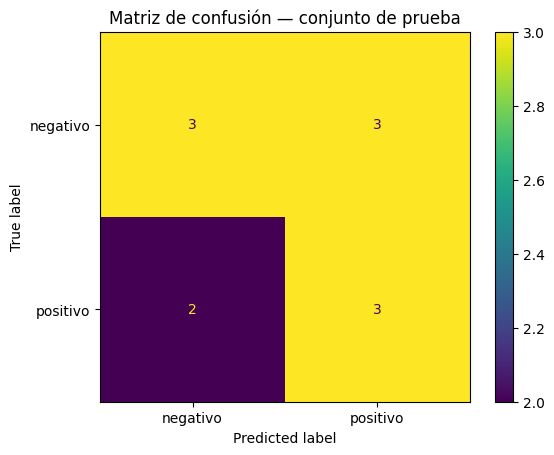

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_test, predicciones)
plt.title("Matriz de confusión — conjunto de prueba")
plt.show()

## 7.4 Inspección de predicciones

In [ ]:
resultados_prueba = pd.DataFrame({
    "texto": X_test.values,
    "real": y_test.values,
    "predicción": predicciones,
})
resultados_prueba["correcta"] = resultados_prueba["real"] == resultados_prueba["predicción"]
resultados_prueba

,texto,real,predicción,correcta
0,La actividad no funcionó,negativo,positivo,False
1,El ejercicio fue frustrante,negativo,negativo,True
2,"Muy buena sesión, quiero profundizar",positivo,positivo,True
3,Quedé satisfecho con la explicación,positivo,negativo,False
4,El notebook es práctico y comprensible,positivo,negativo,False
5,Faltaron ejemplos prácticos,negativo,positivo,False
6,No recomiendo esta clase,negativo,negativo,True
7,La clase fue clara y muy útil,positivo,positivo,True
8,La explicación dejó muchas dudas,negativo,negativo,True
9,Excelente explicación y buenos ejemplos,positivo,positivo,True


## 7.5 Predicción sobre ejemplos nuevos

Las probabilidades son confianza del modelo dentro de sus supuestos, no una garantía de verdad.

In [ ]:
nuevos = [
    "La sesión fue útil aunque un poco rápida",
    "No fue una mala explicación",
    "El notebook parece completo",
    "Esperaba mucho más del ejercicio",
]

pred = modelo.predict(nuevos)
prob = modelo.predict_proba(nuevos)
clases = modelo.named_steps["clasificador"].classes_

for texto_nuevo, etiqueta, probabilidades in zip(nuevos, pred, prob):
    detalle = {clase: round(float(p), 3) for clase, p in zip(clases, probabilidades)}
    print(f"{etiqueta:8} {detalle} | {texto_nuevo}")

negativo {'negativo': 0.556, 'positivo': 0.444} | La sesión fue útil aunque un poco rápida
negativo {'negativo': 0.56, 'positivo': 0.44} | No fue una mala explicación
negativo {'negativo': 0.502, 'positivo': 0.498} | El notebook parece completo
positivo {'negativo': 0.485, 'positivo': 0.515} | Esperaba mucho más del ejercicio


## 7.6 ¿Qué términos usa el modelo?

En regresión logística, coeficientes positivos y negativos permiten inspeccionar qué características empujan la decisión hacia una clase. Esta interpretación es local al dataset y al modelo.

In [ ]:
vectorizador = modelo.named_steps["tfidf"]
clasificador = modelo.named_steps["clasificador"]
terminos = vectorizador.get_feature_names_out()
coeficientes = clasificador.coef_[0]

mas_positivos = np.argsort(coeficientes)[-10:][::-1]
mas_negativos = np.argsort(coeficientes)[:10]

print("Características asociadas con", clasificador.classes_[1])
for i in mas_positivos:
    print(f"{terminos[i]:25} {coeficientes[i]: .3f}")

print("\nCaracterísticas asociadas con", clasificador.classes_[0])
for i in mas_negativos:
    print(f"{terminos[i]:25} {coeficientes[i]: .3f}")

Características asociadas con positivo
bien                       0.246
conceptos quedaron         0.188
funcionó                   0.169
funcionó perfectamente     0.169
perfectamente              0.169
demostración funcionó      0.169
efectiva                   0.162
fue dinámica               0.162
dinámica efectiva          0.162
dinámica                   0.162

Características asociadas con negativo
no                        -0.305
está incompleto           -0.203
incompleto                -0.203
conceptos no              -0.176
no quedaron               -0.176
errores                   -0.170
notebook                  -0.170
el notebook               -0.170
tiene errores             -0.170
notebook tiene            -0.170


# 8. Evaluación responsable, errores y sesgo — 5 minutos

Un sistema de PLN puede fallar aunque el código sea correcto.

### Preguntas mínimas antes de desplegar

1. **Representatividad:** ¿el dataset cubre usuarios, dialectos y dominios reales?
2. **Etiquetas:** ¿quién etiquetó y con qué acuerdo?
3. **Desbalance:** ¿hay clases minoritarias importantes?
4. **Costo del error:** ¿es peor un falso positivo o un falso negativo?
5. **Cambio temporal:** ¿el lenguaje o el proceso cambia con el tiempo?
6. **Privacidad:** ¿hay datos personales o sensibles?
7. **Explicabilidad:** ¿podemos justificar una predicción?
8. **Supervisión humana:** ¿qué decisiones no deben automatizarse por completo?

## Mini análisis de errores

Revise manualmente los errores del conjunto de prueba y los ejemplos nuevos. Busque:

- negación;
- ironía;
- mezcla de opinión positiva y negativa;
- palabras no vistas;
- dependencia del dominio;
- etiquetas discutibles.

In [ ]:
errores = resultados_prueba[~resultados_prueba["correcta"]]
if len(errores) == 0:
    print("No hubo errores en esta partición pequeña. Eso no demuestra generalización.")
else:
    display(errores)

,texto,real,predicción,correcta
0,La actividad no funcionó,negativo,positivo,False
3,Quedé satisfecho con la explicación,positivo,negativo,False
4,El notebook es práctico y comprensible,positivo,negativo,False
5,Faltaron ejemplos prácticos,negativo,positivo,False
10,La práctica no ayudó a aprender,negativo,positivo,False


# 9. Cierre — 2 minutos

## Lo que construimos

```text
Texto
  → normalización y tokenización
  → rasgos lingüísticos
  → TF-IDF
  → clasificador
  → métricas
  → análisis de errores y riesgos
```

## Idea clave

PLN no es solamente entrenar un modelo. Es diseñar y evaluar un sistema completo donde cada decisión de datos, representación, algoritmo y métrica afecta el resultado.

# Extensión A — De técnicas clásicas a embeddings y LLMs

- **BoW/TF-IDF:** representación dispersa, interpretable y dependiente del vocabulario.
- **Word embeddings:** vectores densos que capturan regularidades distribucionales.
- **Embeddings contextuales:** una palabra puede tener diferentes vectores según la oración.
- **Transformers y LLMs:** modelan dependencias de largo alcance y permiten transferencia entre tareas.

Las técnicas clásicas siguen siendo valiosas cuando hay pocos datos, restricciones de cómputo, necesidad de interpretabilidad o dominios muy controlados.

# Extensión B — Ejercicios autónomos

1. Cambie el preprocesamiento para conservar negaciones.
2. Compare unigramas contra unigramas + bigramas.
3. Sustituya regresión logística por `MultinomialNB`.
4. Use validación cruzada.
5. Añada una clase neutral y observe el impacto.
6. Cree un conjunto de prueba con ejemplos ambiguos.
7. Diseñe métricas distintas si el costo de falsos negativos es mayor.
8. Compare similitud TF-IDF con embeddings de oraciones.

# Referencias y recursos

## Fundamentos
- Jurafsky, D., & Martin, J. H. *Speech and Language Processing*, 3rd ed. draft: https://web.stanford.edu/~jurafsky/slp3/
- Manning, C. D., Raghavan, P., & Schütze, H. *Introduction to Information Retrieval*: https://nlp.stanford.edu/IR-book/
- Manning, C. D., & Schütze, H. *Foundations of Statistical Natural Language Processing*.

## Python y herramientas
- NLTK Book: https://www.nltk.org/book/
- NLTK: https://www.nltk.org/
- spaCy 101: https://spacy.io/usage/spacy-101
- Rasgos lingüísticos en spaCy: https://spacy.io/usage/linguistic-features
- Modelos de spaCy: https://spacy.io/models
- Scikit-learn, extracción de características: https://scikit-learn.org/stable/modules/feature_extraction.html
- Ejemplos de clasificación de texto: https://scikit-learn.org/stable/auto_examples/text/

## Continuación hacia modelos modernos
- Hugging Face NLP Course: https://huggingface.co/learn/nlp-course/
- Stanford CS224N: https://web.stanford.edu/class/cs224n/

### Recomendación de lectura
Para esta sesión: NLTK Book capítulos 1, 3, 5 y 6; spaCy 101; y la sección de extracción de características de texto de scikit-learn.